# Importing necessary libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import warnings
warnings.filterwarnings('ignore')

# Loading the dataset

In [28]:
housing = pd.read_csv('housing.csv')

In [5]:

housing.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41,880,129.0,322,126,8.3252,452600,NEAR BAY
1,-122.22,37.86,21,7099,1106.0,2401,1138,8.3014,358500,NEAR BAY
2,-122.24,37.85,52,1467,190.0,496,177,7.2574,352100,NEAR BAY
3,-122.25,37.85,52,1274,235.0,558,219,5.6431,341300,NEAR BAY
4,-122.25,37.85,52,1627,280.0,565,259,3.8462,342200,NEAR BAY


# Dataset Info

In [7]:
print("Dataset shape:", housing.shape)

housing.info()

Dataset shape: (20640, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  int64  
 3   total_rooms         20640 non-null  int64  
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  int64  
 6   households          20640 non-null  int64  
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  int64  
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(4), int64(5), object(1)
memory usage: 1.6+ MB


# Check for mising values

In [9]:
housing.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

# Descriptive Statistics

In [11]:
housing.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


# EDA ANALYSIS

# Visualise  of the target variable

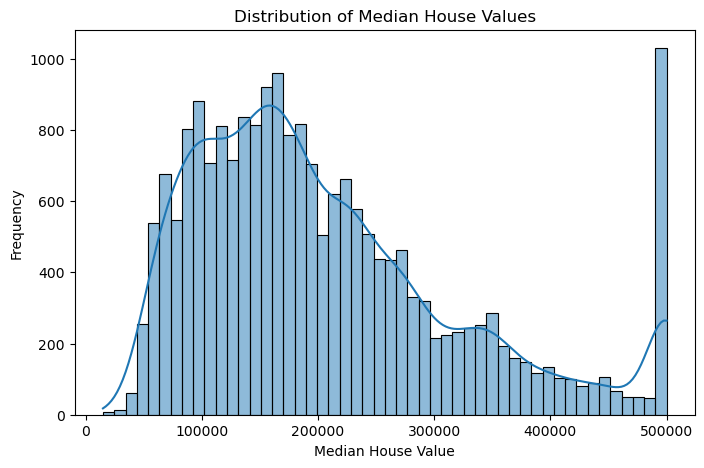

In [13]:
plt.figure(figsize=(8, 5))

sns.histplot(housing['median_house_value'], bins=50, kde=True)

plt.title('Distribution of Median House Values')
plt.xlabel('Median House Value')
plt.ylabel('Frequency')

plt.show()

# Correlation heatmap

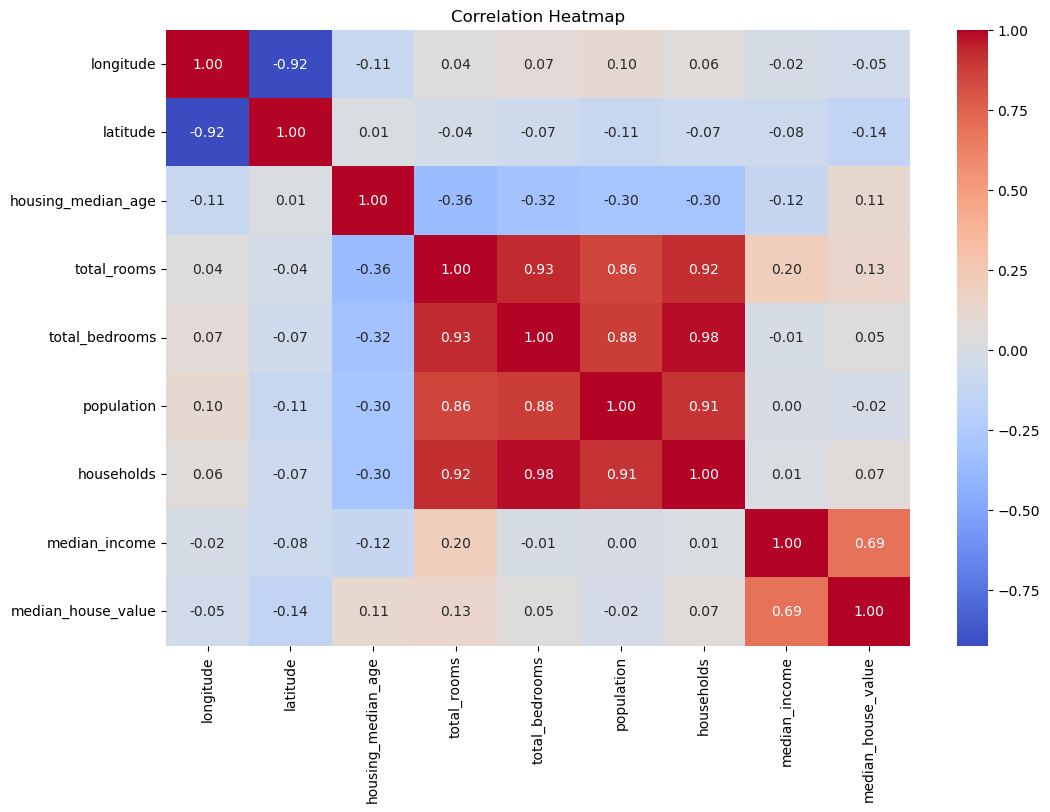

In [15]:
plt.figure(figsize=(12, 8))

correlation = housing.select_dtypes(include=np.number).corr()

sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap')

plt.show()

# relationship between income and house value

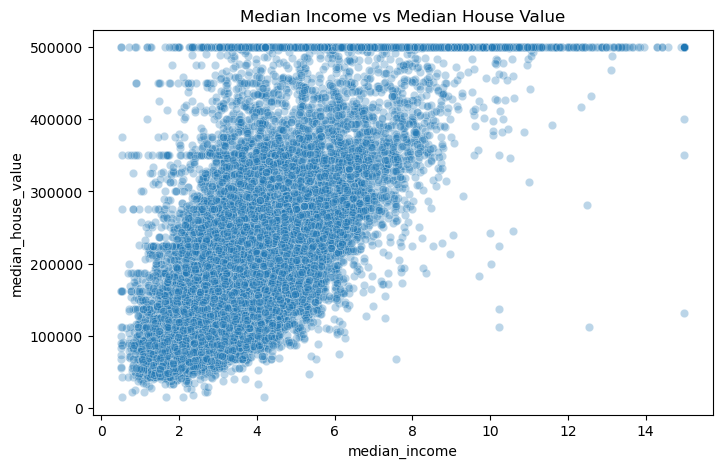

In [17]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=housing,
    x='median_income',
    y='median_house_value',
    alpha=0.3
)

plt.title('Median Income vs Median House Value')
plt.show()

# FEATURE ENGINEERING

# new features:
- Rooms per household
- Bedrooms per room
- Population per household
- Income × housing median age (interaction feature)

In [19]:
housing['rooms_per_household'] = (
    housing['total_rooms'] / housing['households']
)

housing['bedrooms_per_room'] = (
    housing['total_bedrooms'] / housing['total_rooms']
)

housing['population_per_household'] = (
    housing['population'] / housing['households']
)

housing['income_age_interaction'] = (
    housing['median_income'] * housing['housing_median_age']
)

housing.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,rooms_per_household,bedrooms_per_room,population_per_household,income_age_interaction
0,-122.23,37.88,41,880,129.0,322,126,8.3252,452600,NEAR BAY,6.984127,0.146591,2.555556,341.3332
1,-122.22,37.86,21,7099,1106.0,2401,1138,8.3014,358500,NEAR BAY,6.238137,0.155797,2.109842,174.3294
2,-122.24,37.85,52,1467,190.0,496,177,7.2574,352100,NEAR BAY,8.288136,0.129516,2.802260,377.3848
3,-122.25,37.85,52,1274,235.0,558,219,5.6431,341300,NEAR BAY,5.817352,0.184458,2.547945,293.4412
4,-122.25,37.85,52,1627,280.0,565,259,3.8462,342200,NEAR BAY,6.281853,0.172096,2.181467,200.0024


# Separate features and target

In [21]:
X = housing.drop('median_house_value', axis=1)

y = housing['median_house_value']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (20640, 13)
Target shape: (20640,)


# Split the dataset

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (16512, 13)
Testing data: (4128, 13)


#  Data preprocessing

# numerical and categorical columns

In [49]:
numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns

categorical_features = X.select_dtypes(
    include=['object']
).columns

print("Numerical features:", list(numerical_features))
print("Categorical features:", list(categorical_features))

Numerical features: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_age_interaction']
Categorical features: ['ocean_proximity']


# preprocessing pipelines

In [52]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numerical_pipeline, numerical_features),
    ('cat', categorical_pipeline, categorical_features)
])

# Transform the training and testing data

In [57]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (16512, 17)
Processed testing shape: (4128, 17)


#  Train the regression models

In [61]:
from sklearn.linear_model import LinearRegression

ols_model = LinearRegression()

ols_model.fit(X_train_processed, y_train)

ols_predictions = ols_model.predict(X_test_processed)

print("OLS model trained successfully!")

OLS model trained successfully!


# Ridge Regression (L2)

In [64]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV

ridge = Ridge()

ridge_params = {
    'alpha': [0.1, 1, 10, 100, 1000]
}

ridge_grid = GridSearchCV(
    ridge,
    ridge_params,
    cv=5,
    scoring='neg_root_mean_squared_error'
)

ridge_grid.fit(X_train_processed, y_train)

print("Best Ridge alpha:", ridge_grid.best_params_)

Best Ridge alpha: {'alpha': 1}


# Lasso Regression (L1)

In [68]:
from sklearn.linear_model import Lasso

lasso = Lasso(max_iter=10000)

lasso_params = {
    'alpha': [0.1, 1, 10, 100, 1000]
}

lasso_grid = GridSearchCV(
    lasso,
    lasso_params,
    cv=5,
    scoring='neg_root_mean_squared_error'
)

lasso_grid.fit(X_train_processed, y_train)

print("Best Lasso alpha:", lasso_grid.best_params_)

Best Lasso alpha: {'alpha': 1}


# Generate predictions

In [71]:
ridge_predictions = ridge_grid.best_estimator_.predict(
    X_test_processed
)

lasso_predictions = lasso_grid.best_estimator_.predict(
    X_test_processed
)

print("All three models have generated predictions!")

All three models have generated predictions!


In [73]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def evaluate_model(y_true, predictions, model_name):

    rmse = np.sqrt(mean_squared_error(y_true, predictions))
    mae = mean_absolute_error(y_true, predictions)
    r2 = r2_score(y_true, predictions)

    return {
        'Model': model_name,
        'RMSE': rmse,
        'MAE': mae,
        'R2 Score': r2
    }

results = pd.DataFrame([
    evaluate_model(y_test, ols_predictions, 'OLS'),
    evaluate_model(y_test, ridge_predictions, 'Ridge'),
    evaluate_model(y_test, lasso_predictions, 'Lasso')
])

results

,Model,RMSE,MAE,R2 Score
0,OLS,69048.192348,49376.488621,0.636171
1,Ridge,69056.220363,49382.628138,0.636086
2,Lasso,69049.248279,49377.343341,0.636159


#  Visualise predicted vs actual house values

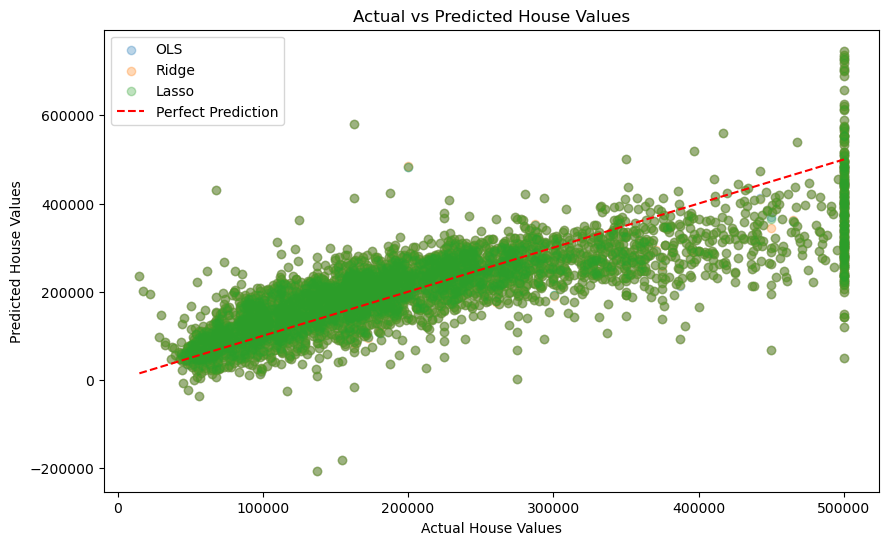

In [76]:
plt.figure(figsize=(10, 6))

plt.scatter(y_test, ols_predictions, alpha=0.3, label='OLS')
plt.scatter(y_test, ridge_predictions, alpha=0.3, label='Ridge')
plt.scatter(y_test, lasso_predictions, alpha=0.3, label='Lasso')

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--',
    label='Perfect Prediction'
)

plt.xlabel('Actual House Values')
plt.ylabel('Predicted House Values')
plt.title('Actual vs Predicted House Values')

plt.legend()
plt.show()

Points closer to the red dashed line represent more accurate predictions.

# Residual distribution curves

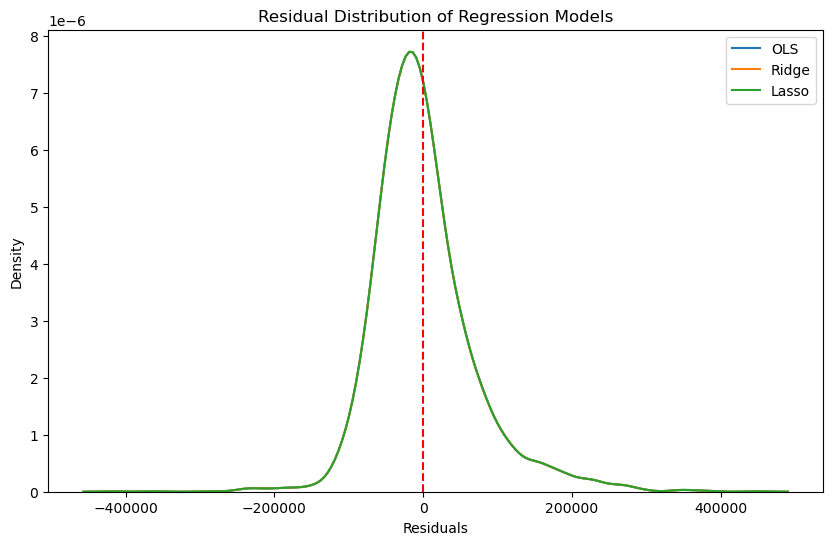

In [80]:
ols_residuals = y_test - ols_predictions
ridge_residuals = y_test - ridge_predictions
lasso_residuals = y_test - lasso_predictions

plt.figure(figsize=(10, 6))

sns.kdeplot(ols_residuals, label='OLS')
sns.kdeplot(ridge_residuals, label='Ridge')
sns.kdeplot(lasso_residuals, label='Lasso')

plt.axvline(0, color='red', linestyle='--')

plt.title('Residual Distribution of Regression Models')
plt.xlabel('Residuals')
plt.ylabel('Density')

plt.legend()
plt.show()